In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/data.yaml
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_01.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_02.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_03.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_04.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_05.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_06.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_07.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_08.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_09.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_11.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_photo_12.jpg
/kaggle/input/datasets/prativakunwar/yolo-asl/yolo/images/train/A_phot

In [3]:
from pathlib import Path
import shutil

# Original YOLO dataset
source = Path("/kaggle/input/datasets/prativakunwar/yolo-asl/yolo")

# New dataset with only one class
destination = Path("/kaggle/working/hand_detection")

# Remove the previous working copy, if it exists
if destination.exists():
    shutil.rmtree(destination)

# Copy the original dataset
shutil.copytree(source, destination)

print("Dataset copied successfully!")

Dataset copied successfully!


In [4]:
# Process training and validation annotations
for split in ["train", "val"]:

    label_folder = destination / "labels" / split

    for label_file in label_folder.glob("*.txt"):

        # Read all annotation lines
        lines = label_file.read_text().splitlines()

        new_lines = []

        for line in lines:

            values = line.split()

            if len(values) >= 5:

                # Change every class ID to 0 (hands)
                values[0] = "0"

                # Keep the original bounding box coordinates
                new_lines.append(" ".join(values))

        # Save the updated annotations
        label_file.write_text("\n".join(new_lines) + "\n")

print("All annotation classes merged into hands!")

All annotation classes merged into hands!


In [5]:
import yaml

yaml_path = destination / "data.yaml"

# Read the existing YAML configuration
with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

# Update dataset paths
data["path"] = str(destination)
data["train"] = "images/train"
data["val"] = "images/val"

# Set only one class
data["nc"] = 1
data["names"] = {0: "hands"}

# Save the updated YAML
with open(yaml_path, "w") as file:
    yaml.safe_dump(data, file, sort_keys=False)

print("Updated YAML:")
print(data)

Updated YAML:
{'path': '/kaggle/working/hand_detection', 'train': 'images/train', 'val': 'images/val', 'names': {0: 'hands'}, 'nc': 1}


In [6]:
from collections import Counter

class_counts = Counter()

for split in ["train", "val"]:

    label_folder = destination / "labels" / split

    for label_file in label_folder.glob("*.txt"):

        for line in label_file.read_text().splitlines():

            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("Class counts:", class_counts)

Class counts: Counter({0: 543})


In [7]:
print(data["nc"])
print(data["names"])
print(data["path"])

1
{0: 'hands'}
/kaggle/working/hand_detection


In [8]:
!pip install ultralytics -q

from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 kB 4.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [9]:
# Load pretrained YOLO model
model = YOLO("yolo11n.pt")

In [10]:
results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    name="asl_hands_detection"
)

Ultralytics 8.4.194 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/hand_detection/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=asl_hands_detection, nbs=64, nms=None, opset=None

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.42G      1.449      1.212      1.605         33        640: 100% ━━━━━━━━━━━━ 32/32 8.7it/s 3.7s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.0it/s 0.3s
                   all         25         24      0.869      0.832      0.926        0.5

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.42G      1.492     0.9929      1.604         28        640: 100% ━━━━━━━━━━━━ 32/32 8.6it/s 3.7s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.6it/s 0.3s
                   all         25         24      0.665      0.833      0.752      0.378

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.42G      1.402     0.8609       1.52         31        640: 100% ━━━━━━━━━━━━ 32/32 8.4it/s 3.8s0.1s
                 Class     Images  Instances      Box(

In [11]:
best_model_path = (
    "/kaggle/working/runs/detect/asl_hands_detection/weights/best.pt"
)

print("Best model:", best_model_path)

Best model: /kaggle/working/runs/detect/asl_hands_detection/weights/best.pt


In [12]:
from pathlib import Path

best_model_path = Path(
    "/kaggle/working/runs/detect/asl_hands_detection/weights/best.pt"
)

if best_model_path.exists():
    print("YOLO best.pt found!")
else:
    print("Model not found. Check the training run directory.")

YOLO best.pt found!


In [13]:
from ultralytics import YOLO

yolo_model = YOLO(str(best_model_path))

print("YOLO model loaded successfully!")
print("Classes:", yolo_model.names)

YOLO model loaded successfully!
Classes: {0: 'hands'}


In [14]:
import random

# Select one image from validation dataset
val_images = list((destination / "images" / "val").glob("*"))

test_image = random.choice(val_images)

print("Testing image:", test_image)

# Detect hands
results = yolo_model.predict(
    source=str(test_image),
    conf=0.25,
    save=True
)

# Display detection result
display(results[0].plot())

Testing image: /kaggle/working/hand_detection/images/val/B_photo_20.jpg

image 1/1 /kaggle/working/hand_detection/images/val/B_photo_20.jpg: 480x640 1 hands, 9.3ms
Speed: 0.7ms preprocess, 9.3ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /kaggle/working/runs/detect/predict


array([[[255, 228, 171],
        [255, 229, 172],
        [255, 229, 172],
        ...,
        [148, 155, 120],
        [146, 153, 118],
        [146, 153, 118]],

       [[253, 226, 169],
        [253, 226, 169],
        [252, 225, 168],
        ...,
        [146, 153, 118],
        [147, 154, 119],
        [149, 156, 121]],

       [[254, 228, 168],
        [252, 226, 166],
        [250, 223, 166],
        ...,
        [148, 153, 121],
        [146, 151, 119],
        [146, 151, 119]],

       ...,

       [[232, 225, 176],
        [232, 225, 176],
        [230, 225, 176],
        ...,
        [124,  76,  70],
        [126,  77,  69],
        [127,  78,  70]],

       [[235, 226, 176],
        [234, 225, 175],
        [232, 225, 175],
        ...,
        [124,  76,  70],
        [125,  77,  71],
        [125,  77,  71]],

       [[237, 226, 174],
        [234, 226, 173],
        [232, 225, 175],
        ...,
        [124,  76,  70],
        [125,  77,  71],
        [126,  78,  72]]

In [15]:
# Get the first detection result
result = results[0]

# Get detected bounding boxes
boxes = result.boxes

print("Number of detected hands:", len(boxes))

# Extract the first detected hand
if len(boxes) > 0:

    # Get bounding box coordinates
    x1, y1, x2, y2 = boxes.xyxy[0].cpu().numpy().astype(int)

    print("Bounding box:", x1, y1, x2, y2)

Number of detected hands: 1
Bounding box: 123 0 378 411


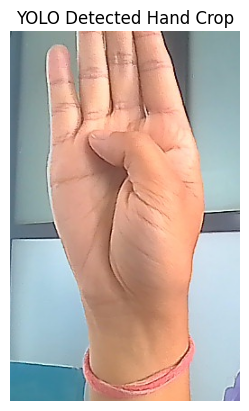

In [16]:
import cv2
import matplotlib.pyplot as plt

# Read original image
image = cv2.imread(str(test_image))

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Crop detected hand
hand_crop = image[y1:y2, x1:x2]

# Display cropped hand
plt.imshow(hand_crop)
plt.axis("off")
plt.title("YOLO Detected Hand Crop")
plt.show()

In [25]:
import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image

In [29]:
class MyCNN(nn.Module):
    def __init__(self):
        super(MyCNN, self).__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28 * 64, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 26)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.fc(x)
        return x

In [30]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cnn_model = MyCNN().to(device)

checkpoint_path = "/kaggle/input/datasets/prativakunwar/mycnn-asl-3/MyCNN_asl (3).pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Select the model weights
if "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

cnn_model.load_state_dict(state_dict)

cnn_model.eval()

print("CNN loaded successfully!")

CNN loaded successfully!


In [31]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Apply CNN transformations
input_tensor = transform(hand_crop)

input_tensor = input_tensor.unsqueeze(0).to(device)
# Convert cropped hand into a tensor
input_tensor = transform(hand_crop)

# Add batch dimension
input_tensor = input_tensor.unsqueeze(0).to(device)

print("Input shape:", input_tensor.shape)

Input shape: torch.Size([1, 3, 224, 224])


In [32]:
# Alphabet class names
classes = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

with torch.no_grad():

    outputs = cnn_model(input_tensor)

    probabilities = torch.softmax(outputs, dim=1)

    confidence, predicted = torch.max(probabilities, dim=1)

    predicted_letter = classes[predicted.item()]

print("Predicted ASL Letter:", predicted_letter)
print("Confidence:", round(confidence.item() * 100, 2), "%")

Predicted ASL Letter: B
Confidence: 33.68 %
